# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 17: Análise de Ortogonalidade, Efeito Oráculo e Grau de Consenso no Random Forest — Classe SMALL

**Autor:** Evandro Rocha (UFRJ / COPPE / PEE)
**Data:** Outubro de 2026

---

## Resumo Executivo da Investigação com Random Forest (RF)

A classe **`SMALL`** (embarcações com comprimento < 50 m, conforme `src/iara/default.py`) foi avaliada em **1.780 instâncias de teste** (arquivo × fold; **476 gravações distintas** de **87 navios**) nos 10 folds do protocolo 5×2cv, com **Random Forest (100 árvores, `class_weight='balanced'`)** nas 4 representações (**MEL, LOFAR, HHT e DEMON**).

O objetivo é confrontar os resultados do SVM (Notebook 13) e do MLP (Notebook 16) com os do Random Forest na classe `SMALL`.

> **Atenção — estes não são os RF do artigo.** Os quatro modelos foram treinados por `scratch/generate_rf_predictions_and_analysis.py` (100 árvores, sem `max_depth`, `class_weight='balanced'`). Para MEL e LOFAR, o script usa caches com **média em 5,12 s** (`mel5s`/`lofar5s`: o arquivo 1 tem 55 frames, contra 551 nas features oficiais de 0,512 s). Por isso, "RF MEL" e "RF LOFAR" aqui (SP 61,50 ± 1,89 e 63,07 ± 1,81) **não são o mesmo modelo** do RF da Tabela 7 do artigo (MEL 62,22 ± 1,86; LOFAR 56,92 ± 1,69). Não compare esses valores como se fossem o mesmo experimento.
>
> O split do 5×2cv é **por gravação** (`exclusive_header='ID'`), como no artigo: o mesmo navio (`Ship ID`) pode aparecer no treino e no teste.
>
> RF DEMON é fraco no problema de 4 classes (SP 44,44 ± 2,24); seus resgates e acertos nesta classe devem ser lidos com isso em mente.

### Principais Descobertas no Random Forest:
1. **Oráculo RF de 85,96% (1.530 / 1.780 instâncias), não realizável; sob erros independentes o esperado seria 95,12%:**
   - Entre as três famílias, o maior oráculo em `SMALL` é o do RF (SVM 81,18%, MLP 76,18%, RF 85,96%). O oráculo usa o rótulo para escolher a entrada.
   - Erro comum (as 4 erram): **250 instâncias (14,04%)**.
2. **Unanimidade 4/4 de 17,13%** (305 instâncias), contra 4,83% no SVM e 4,44% no MLP.
3. **Maior número de resgates exclusivos: DEMON** (172 instâncias = 89 gravações; só 16 gravações são exclusivas do DEMON em todas as aparições).
4. **Votação:** o critério "≥2/4" dá 65,34%, mas conta 244 empates 2×2 como acerto e não é realizável. O **voto real** (pluralidade, empate sorteado) tem recall em `SMALL` de **57,70% ± 4,21** e não difere significativamente do melhor isolado (MEL, 57,87% ± 3,92; F-test 5×2cv, p = 0,812). No SP global, o voto real (62,76) fica contra 63,07 do RF LOFAR (p = 0,783).

In [1]:
# 1. Configuração do Ambiente e Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13,
                     'xtick.labelsize': 10, 'ytick.labelsize': 10, 'figure.titlesize': 15, 'figure.dpi': 150})
pd.set_option('display.precision', 2)
print("Ambiente configurado com sucesso! Bibliotecas prontas.")

Ambiente configurado com sucesso! Bibliotecas prontas.


In [2]:
# Funções de análise de complementaridade (o gerador usa este mesmo código para os números do texto)
import os
import sys
import numpy as np
import pandas as pd

for _p in (os.getcwd(), os.path.join(os.getcwd(), 'src'), os.path.join(os.getcwd(), 'notebooks'), os.path.join(os.getcwd(), 'notebooks', 'src')):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and _p not in sys.path:
        sys.path.insert(0, _p)
import iara_results as R

REPS = ['MEL', 'LOFAR', 'HHT', 'DEMON']
FAMILIAS = {
    # Random Forest (scratch/generate_rf_predictions_and_analysis.py): 100 árvores, sem max_depth,
    # class_weight='balanced'. MEL e LOFAR usam caches com média em 5,12 s (mel5s/lofar5s).
    'RF': {'MEL': 'rf_mel5s_n100_balanced_4c', 'LOFAR': 'rf_lofar5s_n100_balanced_4c',
           'HHT': 'rf_hht_n100_balanced_4c', 'DEMON': 'rf_demon_n100_balanced_4c'},
    # SVM Nyström (Notebooks 13/12/13; scratch/save_svm_all_representations.py)
    'SVM': {'MEL': 'svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0',
            'LOFAR': 'svm_nystroem_6000_lofar_elasticnet_l1r0.15',
            'HHT': 'svm_nystroem_4000_hht_C2.0_elasticnet_l1r0.15_4c',
            'DEMON': 'svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_4c'},
    # MLP (Notebooks 16/15/16; scratch/generate_mlp_predictions_and_analysis.py)
    'MLP': {'MEL': 'mlp', 'LOFAR': 'mlp_lofar',
            'HHT': 'mlp_hht_h32-16_e30_4c', 'DEMON': 'mlp_demon_h32-16_e30_4c'},
}
CLS = {nome: i for i, nome in enumerate(R.CLASSES)}


def nomes(familia):
    return [FAMILIAS[familia][r] for r in REPS]


def ship_ids():
    meta = pd.read_csv(os.path.join(R.ROOT, 'src', 'iara', 'dataset_info', 'iara.csv'),
                       dtype={'ID': str, 'Ship ID': str})
    return dict(zip(meta['ID'].astype(int), meta['Ship ID']))


def instancias(familia, classe):
    """Uma linha por instância (arquivo x fold de teste) da classe, com a predição de cada representação."""
    exps = FAMILIAS[familia]
    al = R.aligned(nomes(familia))
    df = pd.concat([d.assign(fold=k) for k, d in al.items()], ignore_index=True)
    df = df.rename(columns={exps[r]: r for r in REPS})
    df = df[df.Target == CLS[classe]].copy()
    df['Ship ID'] = df.File.map(ship_ids())
    return df


def analise_classe(familia, classe):
    c = CLS[classe]
    d = instancias(familia, classe)
    H = np.column_stack([d[r].values == c for r in REPS])   # acerto de cada representação
    k = H.sum(axis=1)                                         # nº de representações que acertam
    n = len(d)
    out = {'familia': familia, 'classe': classe, 'n_inst': n, 'n_grav': int(d.File.nunique()),
           'n_navios': int(d['Ship ID'].nunique()), 'n_sem_ship': int(d['Ship ID'].isna().sum())}

    rows = []
    for i, r in enumerate(REPS):
        s = R.summary(FAMILIAS[familia][r])
        rows.append({'Representação': r, 'Acertos (instâncias)': int(H[:, i].sum()),
                     'Recall agregado (%)': 100 * H[:, i].mean(),
                     'Recall médio nos folds (%)': s['R_' + classe][0], 'Desvio nos folds': s['R_' + classe][1],
                     'SP global 4c (%)': s['SP'][0], 'Desvio SP': s['SP'][1],
                     'Experimento': FAMILIAS[familia][r]})
    iso = pd.DataFrame(rows).set_index('Representação')
    out['isolado'] = iso
    best = iso['Recall médio nos folds (%)'].idxmax()
    out['melhor'] = best

    orc = R.oracle_recall(nomes(familia)).loc[classe]
    out['oraculo'] = {'acertos': int((k >= 1).sum()), 'agregado': 100 * (k >= 1).mean(),
                      'obs_folds': float(orc.iloc[0]), 'esp_indep': float(orc.iloc[1])}

    niveis = (4, 3, 2, 1, 0)
    cons = pd.DataFrame({'Nível': [f'{j} de 4 acertam' for j in niveis],
                         'Instâncias': [int((k == j).sum()) for j in niveis],
                         'Gravações distintas': [int(d.File[k == j].nunique()) for j in niveis]})
    cons['% da classe'] = 100 * cons['Instâncias'] / n
    out['consenso'] = cons.set_index('Nível')[['Instâncias', '% da classe', 'Gravações distintas']]

    rows = []
    for i, r in enumerate(REPS):
        m = (k == 1) & H[:, i]
        todas = d.assign(excl=m).groupby('File').excl.all()
        rows.append({'Representação': r, 'Instâncias': int(m.sum()), '% da classe': 100 * m.mean(),
                     'Gravações distintas': int(d.File[m].nunique()),
                     'Navios distintos': int(d['Ship ID'][m].nunique()),
                     'Gravações exclusivas em todas as aparições': int(todas.sum())})
    out['exclusivos'] = pd.DataFrame(rows).set_index('Representação')
    m1 = k == 1
    out['excl_total'] = {'inst': int(m1.sum()), 'grav': int(d.File[m1].nunique()),
                         'navios': int(d['Ship ID'][m1].nunique())}

    b = H[:, REPS.index(best)]
    rows = []
    for i, r in enumerate(REPS):
        if r == best:
            continue
        rows.append({'Troca': f'{best} → {r}', 'Mantém acertos': int((b & H[:, i]).sum()),
                     'Perde acertos': int((b & ~H[:, i]).sum()), 'Resgata erros': int((~b & H[:, i]).sum())})
    rev = pd.DataFrame(rows).set_index('Troca')
    rev['% dos acertos perdidos'] = 100 * rev['Perde acertos'] / b.sum()
    rev['% dos erros resgatados'] = 100 * rev['Resgata erros'] / (~b).sum()
    rev['Saldo (instâncias)'] = rev['Resgata erros'] - rev['Perde acertos']
    out['reverso'] = rev

    rows = []
    for i, r in enumerate(REPS):
        e = d.loc[~H[:, i], r]
        row = {'Representação': r, 'Erros (instâncias)': int(len(e))}
        for cc in range(4):
            if cc != c:
                row[f'→ {R.CLASSES[cc]} (%)'] = 100 * (e == cc).mean() if len(e) else np.nan
        rows.append(row)
    out['erros'] = pd.DataFrame(rows).set_index('Representação')

    # "≥2/4" conta como acerto os empates 2x2 (as duas erradas concordam numa mesma classe): não é um voto real
    P = d[REPS].values
    empate = 0
    for row, h in zip(P[k == 2], H[k == 2]):
        errados = row[~h]
        empate += int(errados[0] == errados[1])
    mv = R.majority_vote(nomes(familia))   # voto real: pluralidade, empate sorteado (seed fixa)
    rb = R.fold_metrics(FAMILIAS[familia][best])['R_' + classe]
    F, p = R.f_test_5x2(mv['R_' + classe].values, rb.values)
    best_sp = iso['SP global 4c (%)'].idxmax()
    sb = R.fold_metrics(FAMILIAS[familia][best_sp])['SP']
    Fs, ps = R.f_test_5x2(mv['SP'].values, sb.values)
    out['voto'] = {'ge2_n': int((k >= 2).sum()), 'ge2': 100 * (k >= 2).mean(),
                   'ge3_n': int((k >= 3).sum()), 'ge3': 100 * (k >= 3).mean(), 'empates_2x2': empate,
                   'recall': (mv['R_' + classe].mean(), mv['R_' + classe].std(ddof=0)),
                   'melhor': (rb.mean(), rb.std(ddof=0)), 'F': F, 'p': p,
                   'sp': (mv['SP'].mean(), mv['SP'].std(ddof=0)), 'melhor_sp_rep': best_sp,
                   'melhor_sp': (sb.mean(), sb.std(ddof=0)), 'F_sp': Fs, 'p_sp': ps}
    return out


def tabela_voto(a):
    v = a['voto']
    return pd.DataFrame([
        {'Critério': 'Unanimidade (4/4)', f'Recall {a["classe"]} (%)': a['consenso']['% da classe'].iloc[0],
         'Observação': 'contagem agregada'},
        {'Critério': 'Maioria estrita (≥3/4)', f'Recall {a["classe"]} (%)': v['ge3'],
         'Observação': 'contagem agregada'},
        {'Critério': '≥2/4 (empate 2×2 contado como acerto)', f'Recall {a["classe"]} (%)': v['ge2'],
         'Observação': f'NÃO realizável: inclui {v["empates_2x2"]} empates 2×2'},
        {'Critério': 'Voto real (pluralidade, empate sorteado)', f'Recall {a["classe"]} (%)': v['recall'][0],
         'Observação': f'média ± {v["recall"][1]:.2f} nos folds; F-test vs {a["melhor"]}: p = {v["p"]:.3f}'},
        {'Critério': f'Melhor isolado ({a["melhor"]})', f'Recall {a["classe"]} (%)': v['melhor'][0],
         'Observação': f'média ± {v["melhor"][1]:.2f} nos folds'},
        {'Critério': 'Oráculo (≥1/4)', f'Recall {a["classe"]} (%)': a['oraculo']['agregado'],
         'Observação': f'NÃO realizável; esperado c/ erros independentes: {a["oraculo"]["esp_indep"]:.2f}'},
    ]).set_index('Critério')


def resumo_familias(classe, familias=('SVM', 'MLP', 'RF')):
    A = {f: analise_classe(f, classe) for f in familias}
    rows = {}
    for f, a in A.items():
        iso, ex, v = a['isolado'], a['exclusivos'], a['voto']
        b = a['melhor']
        champ = ex['Instâncias'].idxmax()
        rows[f] = {
            'Melhor isolado: recall médio ± desvio (%)': f"{b}: {iso.loc[b, 'Recall médio nos folds (%)']:.2f} ± {iso.loc[b, 'Desvio nos folds']:.2f}",
            'Oráculo observado (agregado, %)': f"{a['oraculo']['agregado']:.2f}",
            'Oráculo esperado c/ erros independentes (%)': f"{a['oraculo']['esp_indep']:.2f}",
            'Unanimidade 4/4 (%)': f"{a['consenso']['% da classe'].iloc[0]:.2f}",
            'Erro comum 0/4 (%)': f"{a['consenso']['% da classe'].iloc[-1]:.2f}",
            'Maior resgate exclusivo': f"{champ}: {ex.loc[champ, 'Instâncias']} inst. / {ex.loc[champ, 'Gravações distintas']} grav.",
            '≥2/4 com empates (não realizável, %)': f"{v['ge2']:.2f}",
            'Voto real: recall (%) [p vs melhor isolado]': f"{v['recall'][0]:.2f} ± {v['recall'][1]:.2f} [p = {v['p']:.3f}]",
        }
    return pd.DataFrame(rows), A


def f_test_melhores(A, classe, ref='RF'):
    """F-test 5x2cv entre o recall da classe do melhor isolado de `ref` e o das outras famílias."""
    out = {}
    ra = R.fold_metrics(FAMILIAS[ref][A[ref]['melhor']])['R_' + classe].values
    for f, a in A.items():
        if f == ref:
            continue
        rb = R.fold_metrics(FAMILIAS[f][a['melhor']])['R_' + classe].values
        out[f] = R.f_test_5x2(ra, rb)
    return out

## 2. Metodologia Experimental e Base de Dados de Teste

Avaliação sobre a classe real **`SMALL` (Classe 0)** nos conjuntos de teste dos 10 folds do 5×2cv, com as 4 representações (**MEL, LOFAR, HHT e DEMON**) no Random Forest.

**Como contar.** Cada linha das tabelas abaixo é uma **instância arquivo × fold de teste** (predição por arquivo = voto majoritário das janelas, como no pipeline `iara`):
- **1.780 instâncias** de teste de `SMALL`;
- **476 gravações distintas** (cada gravação aparece, em média, **3,74 vezes** como teste nos 10 folds — e não 5 vezes: parte dos arquivos de cada fold vai para validação);
- **87 navios distintos** (`Ship ID` em `src/iara/dataset_info/iara.csv`).

Percentuais "agregados" usam as 1.780 instâncias; "recall médio nos folds" é a média ± desvio (ddof=0) sobre os 10 folds, como no artigo.

> **Nota de reprodutibilidade.** O script de origem desempatava o voto das janelas pela menor classe; aqui usamos `Counter.most_common` (empate → classe da primeira janela), igual a `src/iara/ml/models/trainer.py`. Por isso as contagens diferem da versão anterior deste notebook em poucas instâncias (até ~1 p.p.).

In [3]:
# 2. Desempenho global dos 4 RF e dados da classe SMALL
CLASSE = 'SMALL'
display(R.table([(f'RF {r}', FAMILIAS['RF'][r]) for r in REPS], metrics=('SP', 'ACC', 'F1')))
print('Referência — RF da Tabela 7 do artigo (outro modelo: features de 0,512 s, outra configuração):')
display(pd.DataFrame({f'RF {rep} (artigo)': {m: R.fmt(v) for m, v in R.ARTICLE_TABLE7[('RF', rep)].items()}
                      for rep in ('MEL', 'LOFAR')}).T)

A = analise_classe('RF', CLASSE)
print(f"Instâncias arquivo×fold: {A['n_inst']} | gravações distintas: {A['n_grav']} | "
      f"navios distintos: {A['n_navios']} | aparições médias por gravação: {A['n_inst']/A['n_grav']:.2f}")

,SP,ACC,F1,SMALL,MEDIUM,LARGE,BACKGROUND,Experimento
Modelo,,,,,,,,
RF MEL,61.50 ± 1.89,61.61 ± 1.88,63.27 ± 1.68,57.87,58.72,67.10,62.76,rf_mel5s_n100_balanced_4c
RF LOFAR,63.07 ± 1.81,63.79 ± 1.70,64.92 ± 1.54,47.81,55.64,75.79,75.92,rf_lofar5s_n100_balanced_4c
RF HHT,57.64 ± 2.14,58.11 ± 2.03,60.21 ± 2.04,53.43,46.58,74.07,58.37,rf_hht_n100_balanced_4c
RF DEMON,44.44 ± 2.24,46.08 ± 1.79,47.16 ± 1.94,52.47,35.10,68.79,27.96,rf_demon_n100_balanced_4c


Referência — RF da Tabela 7 do artigo (outro modelo: features de 0,512 s, outra configuração):


,SP,ACC,F1
RF MEL (artigo),62.22 ± 1.86,62.64 ± 1.84,63.79 ± 1.73
RF LOFAR (artigo),56.92 ± 1.69,58.87 ± 1.68,58.00 ± 1.41


Instâncias arquivo×fold: 1780 | gravações distintas: 476 | navios distintos: 87 | aparições médias por gravação: 3.74


## 3. O Efeito Oráculo no Random Forest: Recall Individual vs. Oráculo

O melhor RF isolado em `SMALL` é o **MEL**, com recall médio de **57,87% ± 3,92** nos folds (1.030 de 1.780 instâncias).

O **oráculo** (acerta se ALGUMA das 4 entradas acerta) chega a **85,96% (1.530 instâncias)**. Dois cuidados:
- o oráculo **não é um sistema realizável**: ele usa o rótulo verdadeiro para escolher a entrada;
- se os erros das 4 entradas fossem **independentes**, o esperado seria **95,12%** (1 − ∏(1 − rᵢ), média nos folds), contra **85,96%** observados na mesma média por fold. O oráculo fica **9,17 p.p. abaixo** do esperado sob independência: os erros das representações são **correlacionados** (tendem a cair nos mesmos áudios).

O erro comum (as 4 florestas erram) atinge **250 instâncias (14,04%)**.

,Acertos (instâncias),Recall agregado (%),Recall médio nos folds (%),Desvio nos folds,SP global 4c (%),Desvio SP,Experimento
Representação,,,,,,,
MEL,1030,57.87,57.87,3.92,61.50,1.89,rf_mel5s_n100_balanced_4c
LOFAR,851,47.81,47.81,5.02,63.07,1.81,rf_lofar5s_n100_balanced_4c
HHT,951,53.43,53.43,4.02,57.64,2.14,rf_hht_n100_balanced_4c
DEMON,934,52.47,52.47,7.42,44.44,2.24,rf_demon_n100_balanced_4c


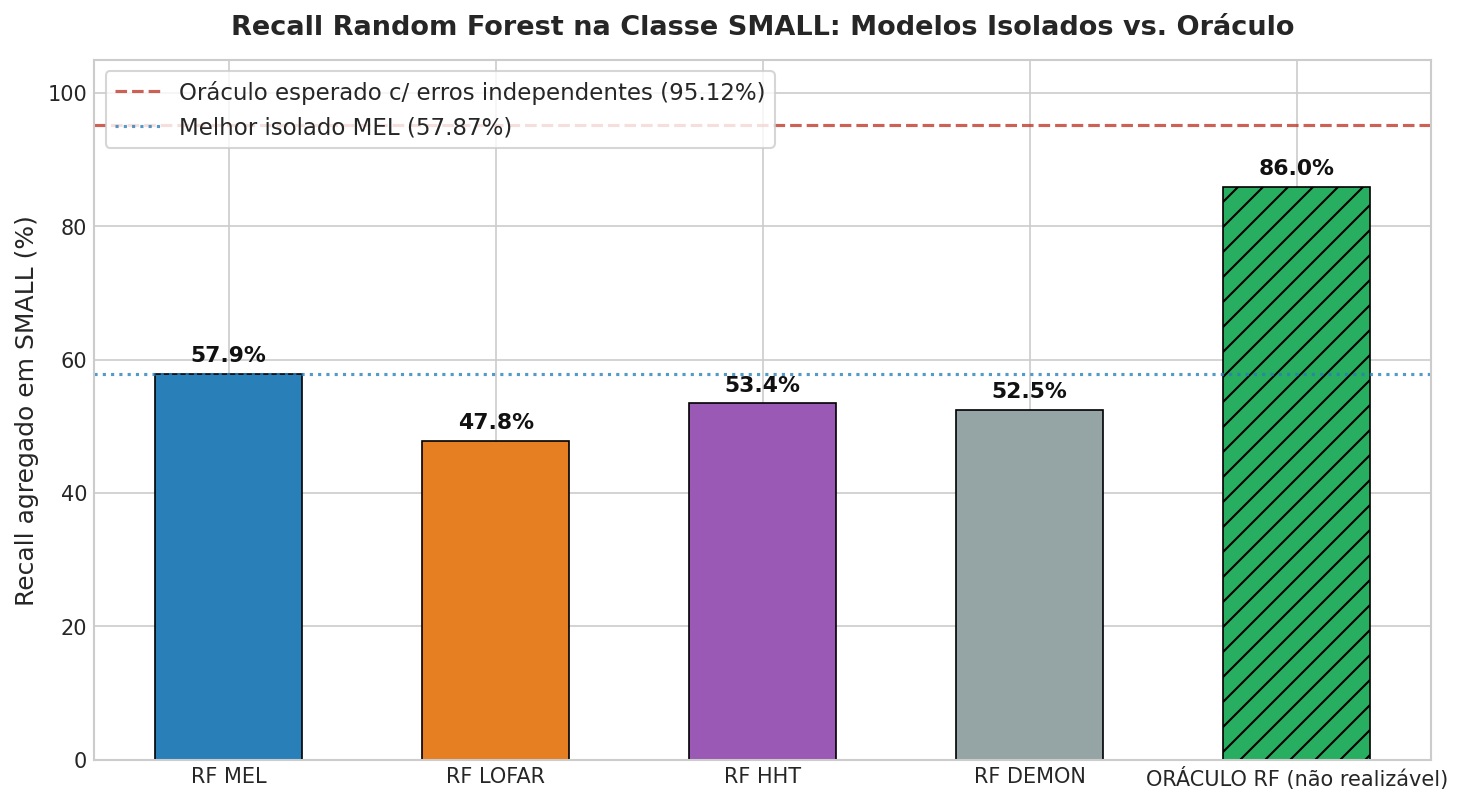

In [4]:
# 3. Gráfico: Desempenho isolado vs. oráculo (observado e esperado sob independência)
iso = A['isolado']
display(iso)
labels = [f'RF {r}' for r in iso.index] + ['ORÁCULO RF (não realizável)']
vals = list(iso['Recall agregado (%)']) + [A['oraculo']['agregado']]
plt.figure(figsize=(10, 5.5))
colors = ['#2980b9', '#e67e22', '#9b59b6', '#95a5a6', '#27ae60']
bars = plt.bar(labels, vals, color=colors, width=0.55, edgecolor='black', linewidth=0.8)
bars[-1].set_hatch('//')
plt.axhline(A['oraculo']['esp_indep'], color='#c0392b', linestyle='--', lw=1.5, alpha=0.8,
            label=f"Oráculo esperado c/ erros independentes ({A['oraculo']['esp_indep']:.2f}%)")
plt.axhline(iso.loc[A['melhor'], 'Recall agregado (%)'], color='#2980b9', linestyle=':', lw=1.5, alpha=0.8,
            label=f"Melhor isolado {A['melhor']} ({iso.loc[A['melhor'], 'Recall agregado (%)']:.2f}%)")
plt.title(f'Recall Random Forest na Classe {CLASSE}: Modelos Isolados vs. Oráculo', fontweight='bold', pad=12)
plt.ylabel(f'Recall agregado em {CLASSE} (%)')
plt.ylim(0, 105)
for bar in bars:
    h = bar.get_height()
    plt.annotate(f'{h:.1f}%', xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 4), textcoords='offset points',
                 ha='center', va='bottom', fontsize=10.5, fontweight='bold', color='#111')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

## 4. Grau de Consenso, Efeito Reverso e Votação em `SMALL` (RF)

### 4.1 Pirâmide de Consenso
- **Unanimidade (4/4 certas):** 305 instâncias (17,13%);
- **Alto consenso (3/4 certas):** 463 instâncias (26,01%);
- **Consenso dividido (2/4 certas):** 395 instâncias (22,19%);
- **Resgate exclusivo (1/4 certa):** 367 instâncias (20,62%);
- **Erro comum (0/4 certas):** 250 instâncias (14,04%).

### 4.2 Efeito reverso a partir do melhor isolado (MEL)
- **MEL → LOFAR:** mantém 652, perde 378 (36,70% dos acertos do MEL) e resgata 199 (26,53% dos erros) — saldo **-179** instâncias;
- **MEL → HHT:** mantém 701, perde 329 (31,94% dos acertos do MEL) e resgata 250 (33,33% dos erros) — saldo **-79** instâncias;
- **MEL → DEMON:** mantém 600, perde 430 (41,75% dos acertos do MEL) e resgata 334 (44,53% dos erros) — saldo **-96** instâncias;

Trocar de entrada sem um critério de seleção reduz os acertos quando o saldo é negativo.

### 4.3 Votação: "≥2/4" vs. voto real
- **≥3/4:** 43,15% (768 instâncias);
- **≥2/4:** 65,34% (1.163 instâncias). Esse número **não é um voto realizável**: conta como acerto os 244 empates 2×2 (duas entradas certas contra duas que concordam numa mesma classe errada);
- **Voto real** (pluralidade entre as 4 entradas, empate sorteado; `R.majority_vote`): recall em `SMALL` de **57,70% ± 4,21**, contra 57,87% ± 3,92 do MEL isolado. Pelo F-test 5×2cv o voto real **não difere significativamente** do melhor isolado nesta classe (p = 0,812);
- No SP global (4 classes), o voto real tem 62,76 ± 2,10, contra 63,07 ± 1,81 do RF LOFAR isolado: **equivalente** (p = 0,783);
- **Oráculo (≥1/4):** 85,96% (1.530 instâncias) — teto não realizável.

,Instâncias,% da classe,Gravações distintas
Nível,,,
4 de 4 acertam,305,17.13,145
3 de 4 acertam,463,26.01,245
2 de 4 acertam,395,22.19,245
1 de 4 acertam,367,20.62,207
0 de 4 acertam,250,14.04,127


,Mantém acertos,Perde acertos,Resgata erros,% dos acertos perdidos,% dos erros resgatados,Saldo (instâncias)
Troca,,,,,,
MEL → LOFAR,652,378,199,36.70,26.53,-179
MEL → HHT,701,329,250,31.94,33.33,-79
MEL → DEMON,600,430,334,41.75,44.53,-96


,Recall SMALL (%),Observação
Critério,,
Unanimidade (4/4),17.13,contagem agregada
Maioria estrita (≥3/4),43.15,contagem agregada
≥2/4 (empate 2×2 contado como acerto),65.34,NÃO realizável: inclui 244 empates 2×2
"Voto real (pluralidade, empate sorteado)",57.70,média ± 4.21 nos folds; F-test vs MEL: p = 0.812
Melhor isolado (MEL),57.87,média ± 3.92 nos folds
Oráculo (≥1/4),85.96,NÃO realizável; esperado c/ erros independente...


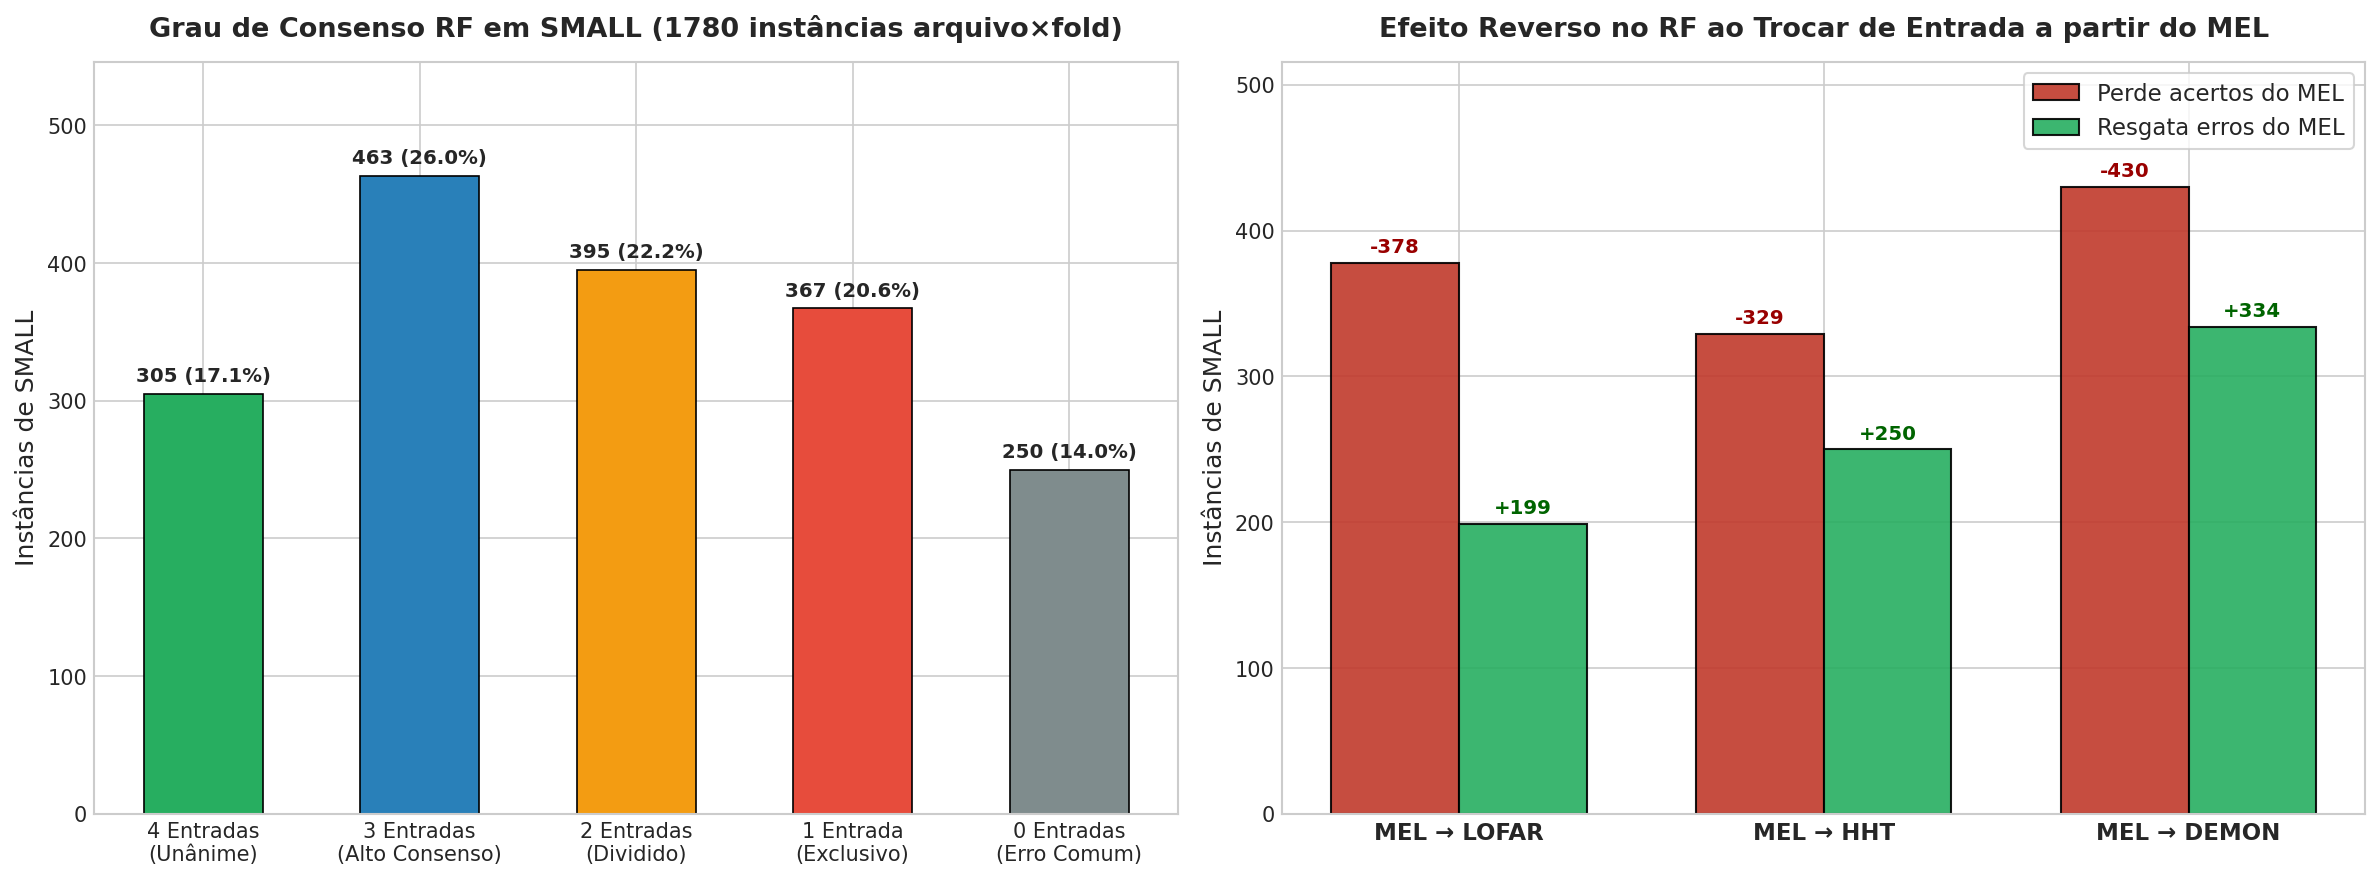

In [5]:
# 4. Visualização do Grau de Consenso e do Efeito Reverso em SMALL (RF)
display(A['consenso'])
display(A['reverso'])
display(tabela_voto(A))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
cons = A['consenso']
labels_cons = ['4 Entradas\n(Unânime)', '3 Entradas\n(Alto Consenso)', '2 Entradas\n(Dividido)',
               '1 Entrada\n(Exclusivo)', '0 Entradas\n(Erro Comum)']
bars1 = ax1.bar(labels_cons, cons['Instâncias'], color=['#27ae60', '#2980b9', '#f39c12', '#e74c3c', '#7f8c8d'],
                edgecolor='black', linewidth=0.8, width=0.55)
ax1.set_title(f"Grau de Consenso RF em {CLASSE} ({A['n_inst']} instâncias arquivo×fold)", fontweight='bold', pad=12)
ax1.set_ylabel(f'Instâncias de {CLASSE}')
ax1.set_ylim(0, cons['Instâncias'].max() * 1.18)
for bar, pct in zip(bars1, cons['% da classe']):
    h = bar.get_height()
    ax1.annotate(f'{int(h)} ({pct:.1f}%)', xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

rev = A['reverso']
x = np.arange(len(rev))
w = 0.35
r1 = ax2.bar(x - w / 2, rev['Perde acertos'], w, label=f"Perde acertos do {A['melhor']}", color='#c0392b', alpha=0.9, edgecolor='black')
r2 = ax2.bar(x + w / 2, rev['Resgata erros'], w, label=f"Resgata erros do {A['melhor']}", color='#27ae60', alpha=0.9, edgecolor='black')
ax2.set_title(f"Efeito Reverso no RF ao Trocar de Entrada a partir do {A['melhor']}", fontweight='bold', pad=12)
ax2.set_ylabel(f'Instâncias de {CLASSE}')
ax2.set_xticks(x)
ax2.set_xticklabels(rev.index, fontweight='bold', fontsize=11)
ax2.set_ylim(0, max(rev['Perde acertos'].max(), rev['Resgata erros'].max()) * 1.2)
ax2.legend(loc='upper right', frameon=True)
for rect in r1:
    ax2.annotate(f'-{int(rect.get_height())}', xy=(rect.get_x() + rect.get_width() / 2, rect.get_height()), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#900')
for rect in r2:
    ax2.annotate(f'+{int(rect.get_height())}', xy=(rect.get_x() + rect.get_width() / 2, rect.get_height()), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#006400')
plt.tight_layout()
plt.show()

## 5. Resgates Exclusivos no Random Forest em `SMALL`

Em **367 instâncias (20,62%)** apenas uma das 4 florestas acertou. Elas correspondem a **207 gravações distintas** e **60 navios distintos** (a mesma gravação aparece em vários folds e pode ser resgatada por entradas diferentes em cada um):

1. **DEMON:** 172 instâncias (9,66%), de 89 gravações e 39 navios; dessas gravações, **16** são resgate exclusivo do DEMON em **todas** as suas aparições de teste.
2. **MEL:** 89 instâncias (5,00%), de 60 gravações e 15 navios; dessas gravações, **1** são resgate exclusivo do MEL em **todas** as suas aparições de teste.
3. **HHT:** 64 instâncias (3,60%), de 50 gravações e 24 navios; dessas gravações, **1** são resgate exclusivo do HHT em **todas** as suas aparições de teste.
4. **LOFAR:** 42 instâncias (2,36%), de 35 gravações e 20 navios; dessas gravações, **0** são resgate exclusivo do LOFAR em **todas** as suas aparições de teste.

O maior número de resgates exclusivos é do **DEMON**. Os resgates são, em grande parte, **instáveis entre folds**: poucas gravações são resgatadas pela mesma entrada em todas as aparições. Um resgate exclusivo também não é aproveitável sem um critério que saiba, sem o rótulo, quando confiar naquela entrada.

,Instâncias,% da classe,Gravações distintas,Navios distintos,Gravações exclusivas em todas as aparições
Representação,,,,,
MEL,89,5.00,60,15,1
LOFAR,42,2.36,35,20,0
HHT,64,3.60,50,24,1
DEMON,172,9.66,89,39,16


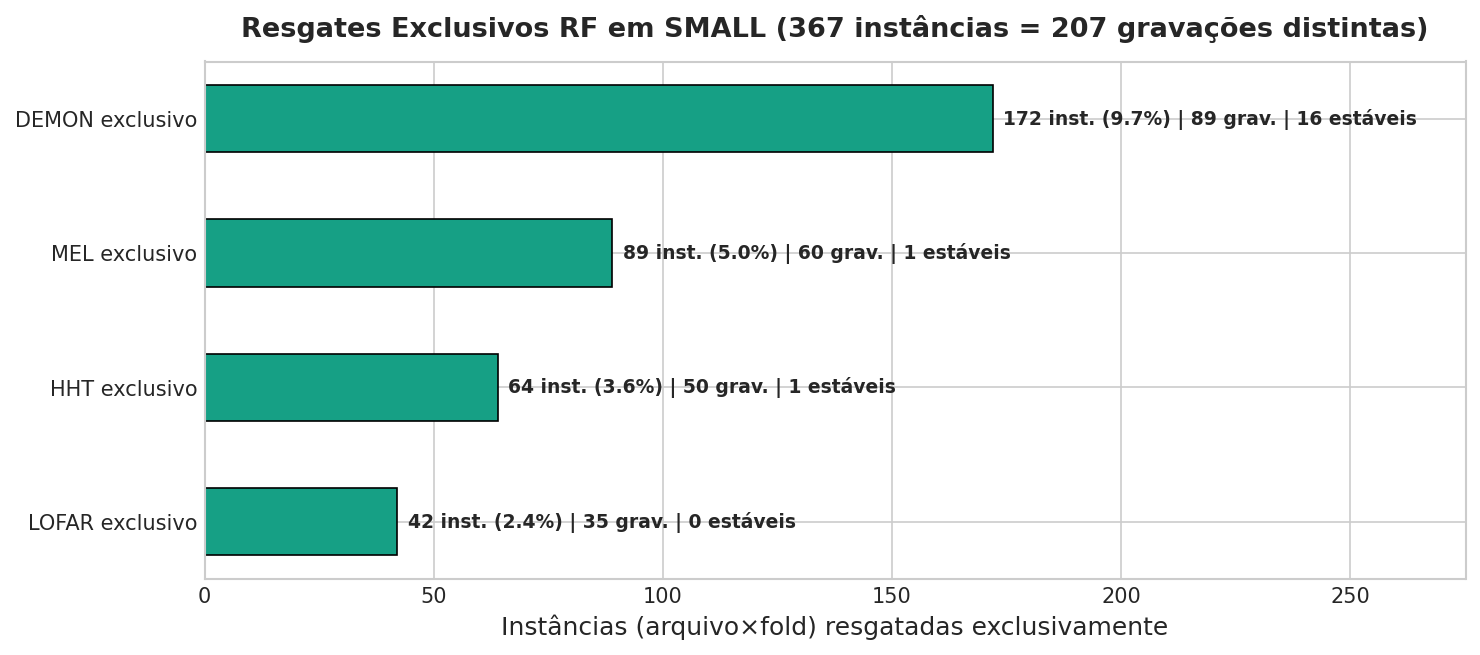

In [6]:
# 5. Gráfico: Resgates Exclusivos na Classe SMALL (RF)
ex = A['exclusivos'].sort_values('Instâncias')
display(A['exclusivos'])
plt.figure(figsize=(10, 4.5))
bars_excl = plt.barh([f'{r} exclusivo' for r in ex.index], ex['Instâncias'], color='#16a085', height=0.5,
                     edgecolor='black', linewidth=0.8)
plt.title(f"Resgates Exclusivos RF em {CLASSE} ({A['excl_total']['inst']} instâncias = {A['excl_total']['grav']} gravações distintas)",
          fontweight='bold', pad=12)
plt.xlabel('Instâncias (arquivo×fold) resgatadas exclusivamente')
plt.xlim(0, ex['Instâncias'].max() * 1.6)
for bar, (r, row) in zip(bars_excl, ex.iterrows()):
    w = bar.get_width()
    plt.annotate(f"{int(w)} inst. ({row['% da classe']:.1f}%) | {int(row['Gravações distintas'])} grav. | "
                 f"{int(row['Gravações exclusivas em todas as aparições'])} estáveis",
                 xy=(w, bar.get_y() + bar.get_height() / 2), xytext=(5, 0), textcoords='offset points',
                 ha='left', va='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Padrões de Erro em `SMALL`: Para Onde Cada Entrada Envia a Embarcação Pequena no RF?

Distribuição dos erros de cada entrada (instâncias agregadas):

| Entrada | Erros | `MEDIUM` | `LARGE` | `BACKGROUND` | Principal destino |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **MEL** | 750 | 51,47% | 44,00% | 4,53% | `MEDIUM` |
| **LOFAR** | 929 | 39,18% | 58,56% | 2,26% | `LARGE` |
| **HHT** | 829 | 22,56% | 72,14% | 5,31% | `LARGE` |
| **DEMON** | 846 | 21,75% | 69,62% | 8,63% | `LARGE` |

> **Hipóteses físicas (não testadas nesta análise).** As explicações abaixo são conjecturas para orientar trabalho futuro; nada nas predições as confirma:
> - DEMON: a cadência de pás/eixo de motores de popa (ex.: 2.500–5.000 RPM ⇒ ~42–83 Hz de rotação de eixo) poderia gerar partições limpas nas árvores;
> - MEL: a energia em altas frequências poderia aproximar embarcações pequenas e `MEDIUM`;
> - LOFAR/HHT/DEMON: a falta de raias tonais fortes ou a modulação por ondas de superfície poderia levar o áudio para `LARGE`.

,Erros (instâncias),→ MEDIUM (%),→ LARGE (%),→ BACKGROUND (%)
Representação,,,,
MEL,750,51.47,44.00,4.53
LOFAR,929,39.18,58.56,2.26
HHT,829,22.56,72.14,5.31
DEMON,846,21.75,69.62,8.63


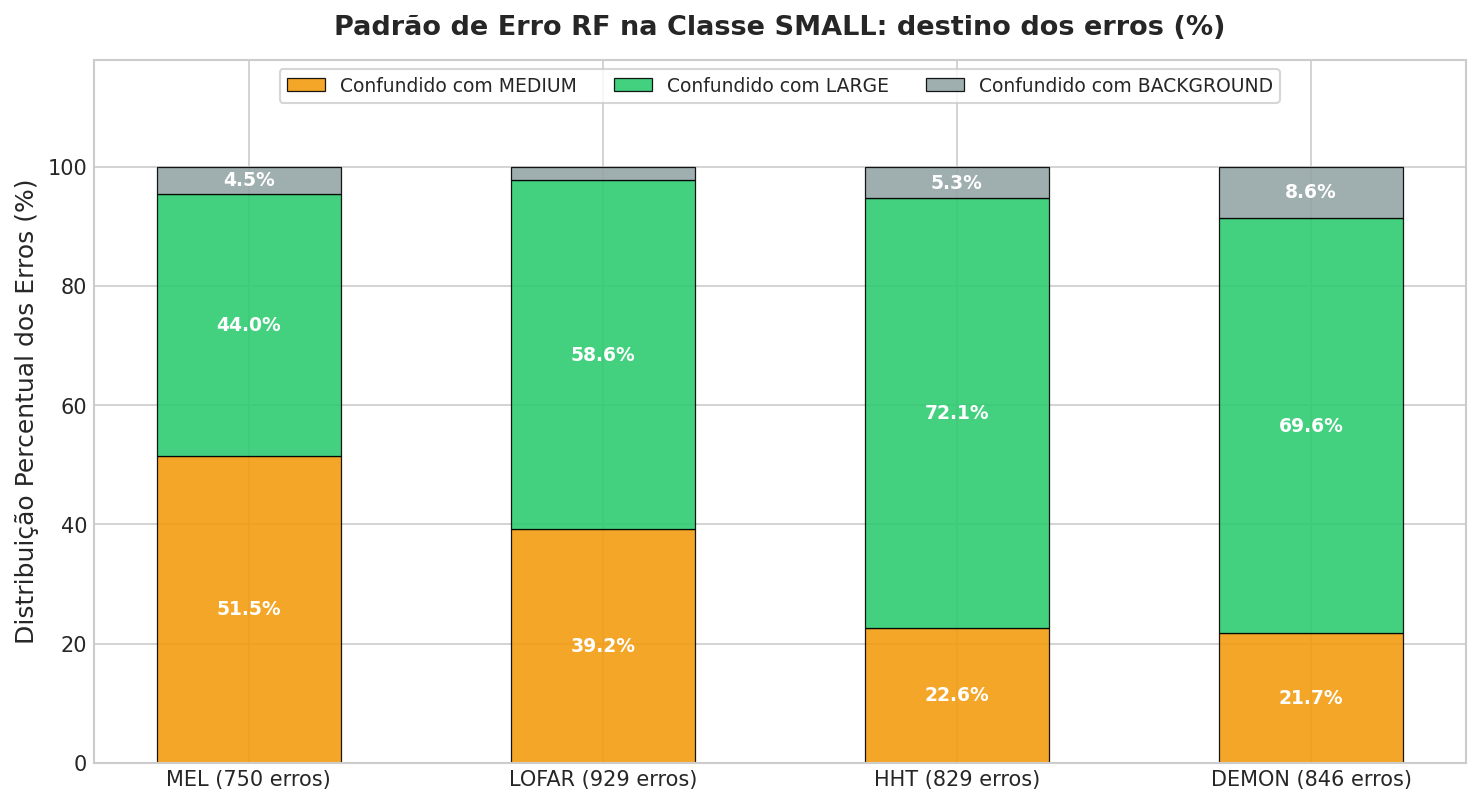

In [7]:
# 6. Gráfico: Destino do Erro em SMALL por Representação (RF)
er = A['erros']
display(er)
cols = [c for c in er.columns if c.startswith('→')]
cores = {'SMALL': '#3498db', 'MEDIUM': '#f39c12', 'LARGE': '#2ecc71', 'BACKGROUND': '#95a5a6'}
plt.figure(figsize=(10, 5.5))
bottom = np.zeros(len(er))
for c in cols:
    alvo = c.replace('→ ', '').replace(' (%)', '')
    vals = er[c].values.astype(float)
    plt.bar(er.index, vals, 0.52, bottom=bottom, label=f'Confundido com {alvo}', color=cores[alvo], alpha=0.9,
            edgecolor='black', linewidth=0.6)
    for i, (vv, bb) in enumerate(zip(vals, bottom)):
        if vv > 3:
            plt.text(i, bb + vv / 2, f'{vv:.1f}%', ha='center', va='center', fontsize=9, fontweight='bold', color='white')
    bottom += vals
plt.xticks(range(len(er)), [f"{r} ({n} erros)" for r, n in zip(er.index, er['Erros (instâncias)'])])
plt.title(f'Padrão de Erro RF na Classe {CLASSE}: destino dos erros (%)', fontweight='bold', pad=12)
plt.ylabel('Distribuição Percentual dos Erros (%)')
plt.ylim(0, 118)
plt.legend(loc='upper center', ncol=3, frameon=True, fontsize=9)
plt.tight_layout()
plt.show()

## 7. Painel Consolidado (figura do script de origem)

A figura abaixo foi gerada por `scratch/generate_rf_predictions_and_analysis.py`, que desempata o voto das janelas pela menor classe. Por isso suas contagens podem diferir das células acima em poucas instâncias; **os valores de referência são os das células deste notebook**. A figura também usa a contagem agregada de instâncias, não de gravações.

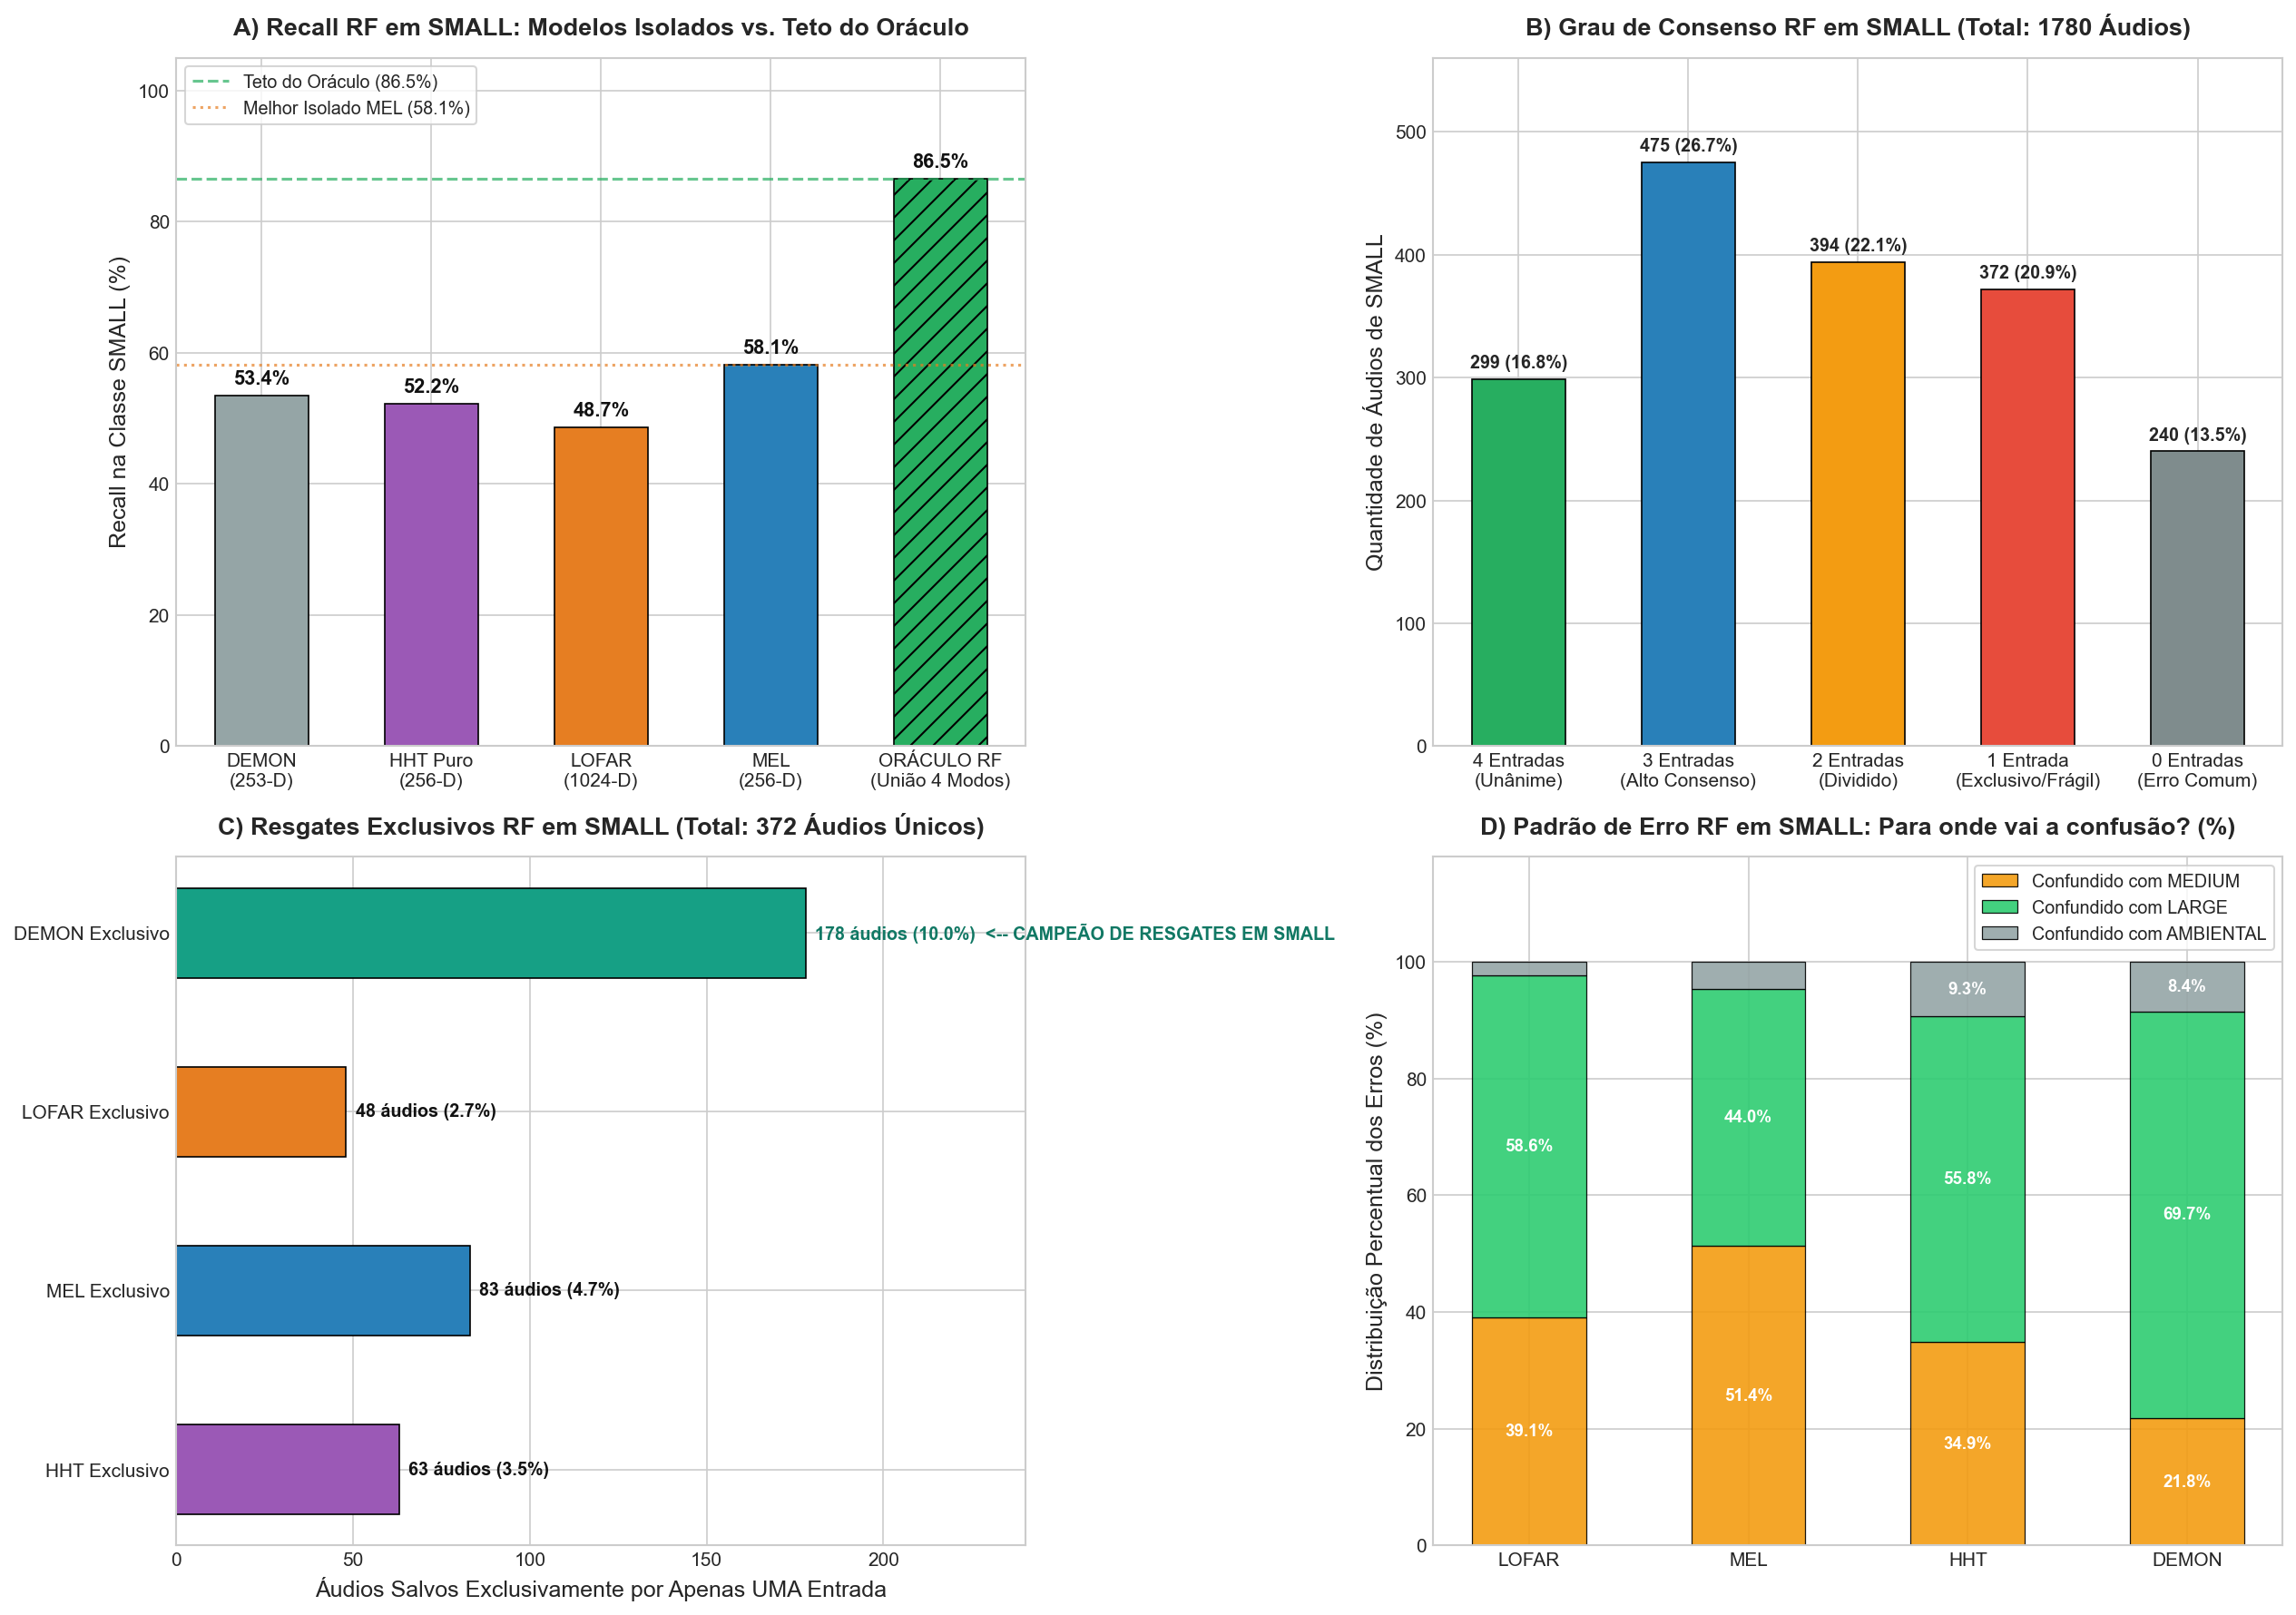

In [8]:
# 7. Exibição do painel salvo em disco (com fallback de caminho para cwd = notebooks/)
from IPython.display import Image
img_name = 'analise_complementaridade_rf_small_oraculo.png'
for img_path in (os.path.join('reports', img_name), os.path.join('..', 'reports', img_name)):
    if os.path.exists(img_path):
        display(Image(filename=img_path))
        break
else:
    print(f"Imagem {img_name} não encontrada em reports/ nem ../reports/. "
          "Execute 'scratch/generate_rf_predictions_and_analysis.py' para gerá-la.")

## 8. Comparativo Trilateral em `SMALL`: SVM Nyström vs. MLP vs. Random Forest

A tabela abaixo é calculada com a mesma função para as três famílias (SVM: Notebook 10; MLP: Notebook 14; RF: Notebook 17). Os experimentos de cada família estão em `FAMILIAS`. As famílias **não são homogêneas**: SVM HHT/DEMON usam m = 4000, os mesmos do Notebook 10 (e são instáveis entre folds); MLP HHT/DEMON vêm de um script ad hoc (30 épocas, sem validação); RF MEL/LOFAR usam as features de 5,12 s.

**Melhor isolado (recall médio em `SMALL` nos folds), com F-test 5×2cv:**
- RF MEL (57,87%) vs. SVM MEL (50,73%): o recall do RF não difere significativamente (p = 0,600).
- RF MEL (57,87%) vs. MLP LOFAR (46,35%): o recall do RF não difere significativamente (p = 0,084).

**Oráculos (não realizáveis):** SVM 81,18% (esperado sob independência 88,51%); MLP 76,18% (esperado sob independência 85,49%); RF 85,96% (esperado sob independência 95,12%). Em todas as famílias o oráculo observado fica abaixo do esperado sob independência, isto é, os erros são correlacionados. Com 4 entradas, um oráculo alto não indica um sistema realizável.

**Unanimidade 4/4:** SVM 4,83%; MLP 4,44%; RF 17,13%.

In [9]:
# 8. Comparativo trilateral calculado (SVM vs MLP vs RF) na classe SMALL
tab, A_fam = resumo_familias(CLASSE)
display(tab)
for f, (F, p) in f_test_melhores(A_fam, CLASSE).items():
    print(f"F-test 5x2cv do recall {CLASSE}: RF {A_fam['RF']['melhor']} vs {f} {A_fam[f]['melhor']} -> F = {F:.2f}, p = {p:.3f}")

,SVM,MLP,RF
Melhor isolado: recall médio ± desvio (%),MEL: 50.73 ± 10.49,LOFAR: 46.35 ± 6.06,MEL: 57.87 ± 3.92
"Oráculo observado (agregado, %)",81.18,76.18,85.96
Oráculo esperado c/ erros independentes (%),88.51,85.49,95.12
Unanimidade 4/4 (%),4.83,4.44,17.13
Erro comum 0/4 (%),18.82,23.82,14.04
Maior resgate exclusivo,HHT: 195 inst. / 147 grav.,DEMON: 158 inst. / 96 grav.,DEMON: 172 inst. / 89 grav.
"≥2/4 com empates (não realizável, %)",53.31,50.00,65.34
Voto real: recall (%) [p vs melhor isolado],46.40 ± 12.01 [p = 0.414],42.30 ± 6.94 [p = 0.315],57.70 ± 4.21 [p = 0.812]


F-test 5x2cv do recall SMALL: RF MEL vs SVM MEL -> F = 0.88, p = 0.600
F-test 5x2cv do recall SMALL: RF MEL vs MLP LOFAR -> F = 3.62, p = 0.084


## 9. Ensemble RF por Média de Probabilidades

A Seção 4.3 mostra que o critério "≥2/4 acertam" (65,34% em `SMALL`) usa o rótulo e não é uma regra de decisão. Uma regra realizável que usa a mesma ideia é combinar as probabilidades dos RF: o modelo **`ensemble_rf`** (`scratch/ensemble_rf_prob_5x2cv.py`) não treina nada novo. Para cada gravação de teste:

1. em cada RF, tira a média das probabilidades (`predict_proba`) das janelas da gravação — as janelas não coincidem entre representações (MEL/LOFAR em 5 s, HHT/DEMON em 5,12 s), por isso a média é por gravação;
2. tira a média dessas probabilidades entre as representações (pesos iguais);
3. prediz a classe de maior probabilidade.

O empate entre classes, problema do voto por maioria (2 RF contra 2), praticamente não ocorre com probabilidades contínuas. Os folds e o treino de cada RF são os mesmos dos modelos isolados; os números são de 4 classes (não há RF MEL/LOFAR em 3 classes).

Duas variantes:
- **4 representações** (MEL + LOFAR + HHT + DEMON): a proposta original, definida antes de ver os resultados;
- **sem DEMON**: **exploratória** — a exclusão do DEMON (SP 44,44 isolado) foi decidida depois de ver o desempenho no teste, então seu resultado está otimista e não deve ser apresentado como escolha a priori.

In [10]:
# 9. Ensemble RF por média de probabilidades (scratch/ensemble_rf_prob_5x2cv.py)
RF = FAMILIAS['RF']
ENS4, ENS3 = 'ensemble_rf_prob_mel-lofar-hht-demon_4c', 'ensemble_rf_prob_mel-lofar-hht_4c'
linhas = [(f'RF {r}', RF[r]) for r in REPS] + [('Ensemble RF (4 rep., média de prob.)', ENS4),
                                              ('Ensemble RF sem DEMON (exploratório)', ENS3)]
tab_ens = R.table(linhas, metrics=('SP', 'ACC', 'F1'))
mv = R.majority_vote(nomes('RF'))
tab_ens.loc['Voto real (pluralidade, empate sorteado)'] = (
    [f"{mv[m].mean():.2f} ± {mv[m].std(ddof=0):.2f}" for m in ('SP', 'ACC', 'F1')]
    + [round(mv['R_' + c].mean(), 2) for c in R.CLASSES] + ['(calculado aqui)'])
display(tab_ens)

testes = []
for ens_lab, ens in (('4 rep.', ENS4), ('sem DEMON', ENS3)):
    fe = R.fold_metrics(ens)
    for ref in ('LOFAR', 'MEL'):
        fr = R.fold_metrics(RF[ref])
        for m in ['SP'] + ['R_' + c for c in R.CLASSES]:
            F, p = R.f_test_5x2(fe[m].values, fr[m].values)
            testes.append({'Ensemble': ens_lab, 'vs': f'RF {ref}', 'Métrica': m.replace('R_', 'recall '),
                           'Δ (p.p.)': round(fe[m].mean() - fr[m].mean(), 2), 'F': round(F, 2), 'p': round(p, 3)})
    F, p = R.f_test_5x2(fe['SP'].values, mv['SP'].values)
    testes.append({'Ensemble': ens_lab, 'vs': 'voto real', 'Métrica': 'SP',
                   'Δ (p.p.)': round(fe['SP'].mean() - mv['SP'].mean(), 2), 'F': round(F, 2), 'p': round(p, 3)})
display(pd.DataFrame(testes).set_index(['Ensemble', 'vs', 'Métrica']))

,SP,ACC,F1,SMALL,MEDIUM,LARGE,BACKGROUND,Experimento
Modelo,,,,,,,,
RF MEL,61.50 ± 1.89,61.61 ± 1.88,63.27 ± 1.68,57.87,58.72,67.10,62.76,rf_mel5s_n100_balanced_4c
RF LOFAR,63.07 ± 1.81,63.79 ± 1.70,64.92 ± 1.54,47.81,55.64,75.79,75.92,rf_lofar5s_n100_balanced_4c
RF HHT,57.64 ± 2.14,58.11 ± 2.03,60.21 ± 2.04,53.43,46.58,74.07,58.37,rf_hht_n100_balanced_4c
RF DEMON,44.44 ± 2.24,46.08 ± 1.79,47.16 ± 1.94,52.47,35.10,68.79,27.96,rf_demon_n100_balanced_4c
"Ensemble RF (4 rep., média de prob.)",63.92 ± 2.07,64.36 ± 1.99,66.40 ± 1.90,59.55,51.74,78.18,67.96,ensemble_rf_prob_mel-lofar-hht-demon_4c
Ensemble RF sem DEMON (exploratório),64.60 ± 1.78,64.97 ± 1.69,66.68 ± 1.57,58.54,53.89,75.93,71.53,ensemble_rf_prob_mel-lofar-hht_4c
"Voto real (pluralidade, empate sorteado)",62.76 ± 2.10,63.24 ± 2.05,65.19 ± 1.81,57.70,50.40,77.10,67.76,(calculado aqui)


Δ (p.p.)      F         p
Ensemble  vs        Métrica                                     
4 rep.    RF LOFAR  SP                     0.85   1.04  5.14e-01
                    recall SMALL          11.74   9.74  1.10e-02
                    recall MEDIUM         -3.89   1.10  4.89e-01
                    recall LARGE           2.38   1.38  3.81e-01
                    recall BACKGROUND     -7.96  12.36  6.00e-03
          RF MEL    SP                     2.42   1.37  3.81e-01
                    recall SMALL           1.69   2.59  1.53e-01
                    recall MEDIUM         -6.98   5.86  3.20e-02
                    recall LARGE          11.07   5.04  4.40e-02
                    recall BACKGROUND      5.20   2.01  2.28e-01
          voto real SP                     1.15   1.20  4.44e-01
sem DEMON RF LOFAR  SP                     1.53   1.62  3.09e-01
                    recall SMALL          10.73   7.52  1.90e-02
                    recall MEDIUM         -1.74   0.65  7.37e-01
                    recall LARGE           0.14   0.59  7.78e-01
                    recall BACKGROUND     -4.39   3.39  9.50e-02
          RF MEL    SP                     3.10   2.73  1.40e-01
                    recall SMALL           0.67   1.93  2.42e-01
                    recall MEDIUM         -4.83   3.69  8.10e-02
                    recall LARGE           8.83   5.32  3.90e-02
                    recall BACKGROUND      8.78   6.00  3.10e-02
          voto real SP                     1.84   2.86  1.29e-01

**Leitura.**
- **SP global:** o ensemble de 4 representações tem SP 63,92 ± 2,07, contra 63,07 ± 1,81 do RF LOFAR (**sem diferença significativa**; F-test 5×2cv, p = 0,514) e 61,50 ± 1,89 do RF MEL (**sem diferença significativa**; p = 0,381). A variante sem DEMON chega a 64,60 ± 1,78 (p = 0,309 vs RF LOFAR).
- **`SMALL`:** o recall sobe de 47,81% (RF LOFAR) para 59,55% (p = 0,011). Contra o RF MEL (57,87%), a diferença é p = 0,153. Os 65,34% do critério "≥2/4" não são alcançados: parte deles vinha de empates 2×2 contados como acerto.
- **Troca, não ganho líquido:** em relação ao RF LOFAR, o ensemble perde recall em `MEDIUM` (-3,89 p.p.; p = 0,489), `BACKGROUND` (-7,96 p.p.; p = 0,006). O ganho em `SMALL` vem, em parte, de redistribuir acertos entre as classes.
- **Uso recomendado:** linha de base simples de fusão (sem treino adicional) para comparar com os sistemas de gating do Notebook 26, e não como um modelo que supera o melhor RF isolado.